## Loading Data& Products

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)

# 1. Load local Parquet files
df_products = pd.read_parquet("D:\ALL Projects\SIC Graduation Project - Part AI\data\dim_product_clean.parquet")
df_events = pd.read_parquet(r"D:\ALL Projects\SIC Graduation Project - Part AI\data\fact_events_clean.parquet")

# 2. Filter out placeholder row (product_id = -1)
df_products = df_products[df_products['product_id'] != -1]

# 1. PRODUCTS DATASET DIAGNOSIS
print("--- 1. PRODUCTS DATA DIAGNOSIS ---")
print(f"Total Rows & Columns (Shape): {df_products.shape}")
print(f"Unique Products Count: {df_products['product_id'].nunique():,}")
print(f"Unique Brands Count: {df_products['brand'].nunique():,}")
print(f"Unique Categories (Level 1): {df_products['category_level1'].nunique():,}")
print(f"Unique Categories (Level 2): {df_products['category_level2'].nunique():,}")
print(f"Unique Categories (Level 3): {df_products['category_level3'].nunique():,}")

print("\nColumns & Data Types (Products):")
print(df_products.dtypes)

print("\nMissing Values Count (Products):")
print(df_products.isnull().sum())

# Print complete price summary cleanly
stats = df_products['base_price'].describe()
print("\nPrice Distribution Summary:")
print(f"  • Count : {stats['count']:,.0f}")
print(f"  • Mean  : {stats['mean']:.2f}")
print(f"  • Std   : {stats['std']:.2f}")
print(f"  • Min   : {stats['min']:.2f}")
print(f"  • 25%   : {stats['25%']:.2f}")
print(f"  • 50%   : {stats['50%']:.2f} (Median)")
print(f"  • 75%   : {stats['75%']:.2f}")
print(f"  • Max   : {stats['max']:.2f}")

--- 1. PRODUCTS DATA DIAGNOSIS ---
Total Rows & Columns (Shape): (117286, 7)
Unique Products Count: 117,286
Unique Brands Count: 2,641
Unique Categories (Level 1): 14
Unique Categories (Level 2): 57
Unique Categories (Level 3): 82

Columns & Data Types (Products):
product_id           int64
category_code          str
category_level1        str
category_level2        str
category_level3        str
brand                  str
base_price         float64
dtype: object

Missing Values Count (Products):
product_id         0
category_code      0
category_level1    0
category_level2    0
category_level3    0
brand              0
base_price         0
dtype: int64

Price Distribution Summary:
  • Count : 117,286
  • Mean  : 181.21
  • Std   : 300.31
  • Min   : 0.79
  • 25%   : 26.38
  • 50%   : 75.25 (Median)
  • 75%   : 192.80
  • Max   : 2574.07


## Events

In [2]:
# 2. EVENTS DATASET DIAGNOSIS
print("--- 2. EVENTS DATA DIAGNOSIS ---")
print(f"Total Interaction Events (Shape): {df_events.shape}")
print(f"Unique Users Count: {df_events['user_key'].nunique():,}")
print(f"Median Events per User: {df_events.groupby('user_key').size().median()}")

print("\nColumns & Data Types (Events):")
print(df_events.dtypes)

print("\nMissing Values Count (Events):")
print(df_events.isnull().sum())

print("\nEvent Types Breakdown (%):")
print(df_events['event_type_key'].value_counts(normalize=True) * 100)

--- 2. EVENTS DATA DIAGNOSIS ---
Total Interaction Events (Shape): (8248730, 4)
Unique Users Count: 940,426
Median Events per User: 4.0

Columns & Data Types (Events):
user_key                   int64
product_id                 int64
event_type_key             int64
event_ts          datetime64[us]
dtype: object

Missing Values Count (Events):
user_key          0
product_id        0
event_type_key    0
event_ts          0
dtype: int64

Event Types Breakdown (%):
event_type_key
1    94.970886
2     2.838995
4     2.190119
Name: proportion, dtype: float64


## Duplicates & Overlap

In [3]:
# --- 3. DEDUPLICATION & IMPLICIT SIGNAL EXTRACTION (BEFORE SPLIT) ---
print(f"Original Events Count (with duplicates): {len(df_events):,}")

# Instead of blindly dropping duplicates, we aggregate duplicate interactions 
# to capture 'Repeat Views' as an implicit behavioral signal.
df_events_clean = (
    df_events
    .groupby(['user_key', 'product_id', 'event_type_key'], as_index=False)
    .size()
    .rename(columns={'size': 'interaction_count'})
)

print(f"Cleaned Events Count (after aggregation): {len(df_events_clean):,}")
print(f"Reduction in rows / duplicates handled: {len(df_events) - len(df_events_clean):,}")

print("\n" + "="*60 + "\n")

# --- 4. CATALOG COVERAGE & OVERLAP (USING CLEANED EVENTS) ---
active_products_in_events = df_events_clean['product_id'].nunique()
catalog_products = df_products['product_id'].nunique()
overlap_percentage = (active_products_in_events / catalog_products) * 100

print("--- 4. CATALOG COVERAGE & OVERLAP ---")
print(f"Active Products in Cleaned Events: {active_products_in_events:,} / {catalog_products:,} ({overlap_percentage:.2f}%)")

Original Events Count (with duplicates): 8,248,730
Cleaned Events Count (after aggregation): 5,056,471
Reduction in rows / duplicates handled: 3,192,259


--- 4. CATALOG COVERAGE & OVERLAP ---
Active Products in Cleaned Events: 115,543 / 117,286 (98.51%)


## Checking Skew& Outliering

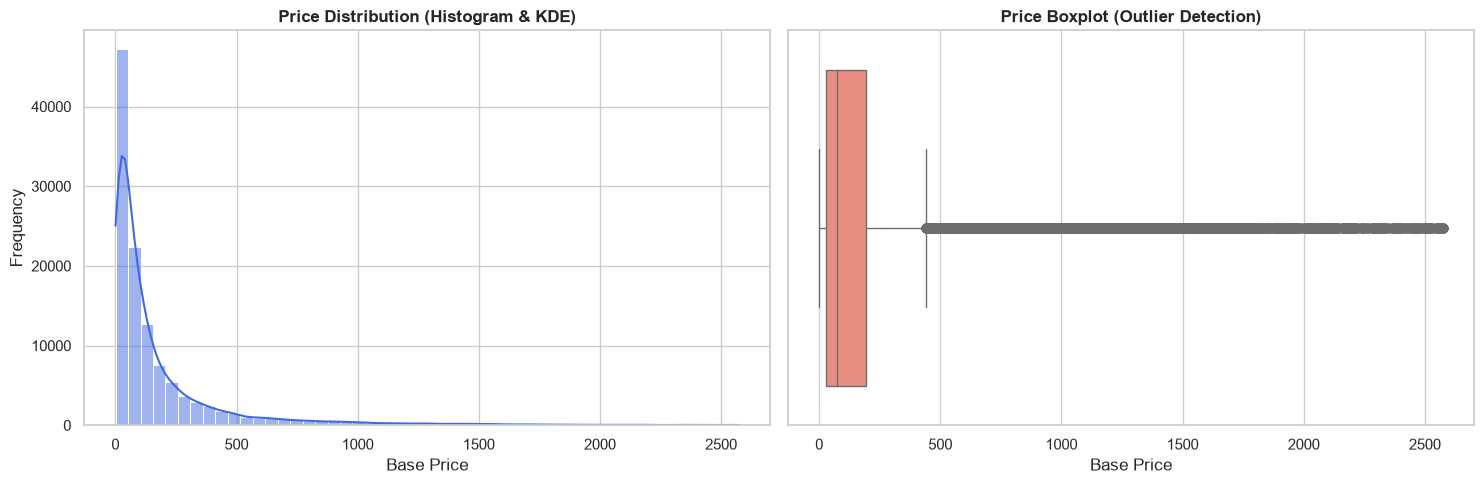

--- PRICE STATISTICAL DIAGNOSIS ---
Skewness Value : 3.64
IQR (Q3 - Q1)  : 166.42
Upper Bound    : 442.43
Outliers Count : 12,080 out of 117,286 (10.30%)


In [4]:
# 1. Setup plot figure
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(15, 5))
sns.set_theme(style="whitegrid")

# 2. Plot Distribution (Histogram + KDE)
plt.subplot(1, 2, 1)
sns.histplot(df_products['base_price'], kde=True, color='royalblue', bins=50)
plt.title('Price Distribution (Histogram & KDE)', fontsize=12, fontweight='bold')
plt.xlabel('Base Price')
plt.ylabel('Frequency')

# 3. Plot Boxplot for Outlier Detection
plt.subplot(1, 2, 2)
sns.boxplot(x=df_products['base_price'], color='salmon')
plt.title('Price Boxplot (Outlier Detection)', fontsize=12, fontweight='bold')
plt.xlabel('Base Price')

plt.tight_layout()
plt.show()

# 4. Statistical calculations for Skewness and Outliers (IQR Method)
skewness = df_products['base_price'].skew()

Q1 = df_products['base_price'].quantile(0.25)
Q3 = df_products['base_price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((df_products['base_price'] < lower_bound) | (df_products['base_price'] > upper_bound)).sum()
outliers_percentage = (outliers_count / len(df_products)) * 100

print("--- PRICE STATISTICAL DIAGNOSIS ---")
print(f"Skewness Value : {skewness:.2f}")
print(f"IQR (Q3 - Q1)  : {IQR:.2f}")
print(f"Upper Bound    : {upper_bound:.2f}")
print(f"Outliers Count : {outliers_count:,} out of {len(df_products):,} ({outliers_percentage:.2f}%)")